Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the official UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Load the features and target
X_all = heart_disease.data.features
y_all = heart_disease.data.targets

# Display dataset information
print("Dataset downloaded successfully!")
print("Feature dataset shape:", X_all.shape)
print("Target dataset shape:", y_all.shape)

print("\nFeature column names:")
print(X_all.columns.tolist())

print("\nFirst five feature rows:")
display(X_all.head())

print("\nFirst five target rows:")
display(y_all.head())

print("\nMissing values in each feature:")
print(X_all.isnull().sum())

Dataset downloaded successfully!
Feature dataset shape: (303, 13)
Target dataset shape: (303, 1)

Feature column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

First five feature rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



First five target rows:


,num
0,0
1,2
2,1
3,0
4,0



Missing values in each feature:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


In [1]:
import pandas as pd
import numpy as np
import os

# Check the current working directory
print("Current directory:", os.getcwd())

# Load the processed Cleveland dataset
file_path = "processed.cleveland.data"

column_names = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

heart_df = pd.read_csv(
    file_path,
    header=None,
    names=column_names,
    na_values="?"
)

print("\nDataset loaded successfully!")
print("Dataset shape:", heart_df.shape)

print("\nFirst 5 rows:")
display(heart_df.head())

print("\nMissing values:")
print(heart_df.isnull().sum())

Current directory: D:\Python Programes\ML\Uni\ML_assignment_2\ML_Assignment_2\Heart_Disease

Dataset loaded successfully!
Dataset shape: (303, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [2]:
from sklearn.model_selection import train_test_split

# Select exactly four input features
selected_features = ["age", "sex", "cp", "thalach"]

X = heart_df[selected_features].copy()

# Convert target into binary classification:
# 0 = No disease indicated
# 1 = Disease indicated
y = (heart_df["num"] > 0).astype(int)

# Check for missing values in selected data
print("Missing values in selected features:")
print(X.isnull().sum())

# Display class distribution
print("\nTarget distribution:")
print(y.value_counts().sort_index().rename(index={
    0: "No disease indicated",
    1: "Disease indicated"
}))

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nData preparation completed!")
print("Selected features:", selected_features)
print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Missing values in selected features:
age        0
sex        0
cp         0
thalach    0
dtype: int64

Target distribution:
num
No disease indicated    164
Disease indicated       139
Name: count, dtype: int64

Data preparation completed!
Selected features: ['age', 'sex', 'cp', 'thalach']
Training input shape: (242, 4)
Testing input shape: (61, 4)
Training target shape: (242,)
Testing target shape: (61,)


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset again
column_names = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

heart_df = pd.read_csv(
    "processed.cleveland.data",
    header=None,
    names=column_names,
    na_values="?"
)

# Select exactly four input features
selected_features = ["age", "sex", "cp", "thalach"]
X = heart_df[selected_features].copy()

# Convert the target to binary classification
y = (heart_df["num"] > 0).astype(int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preparation completed!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Data preparation completed!
X_train: (242, 4)
X_test: (61, 4)
y_train: (242,)
y_test: (61,)


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", random_state=42))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Model type:", type(model.named_steps["classifier"]).__name__)
print("Number of input features:", model.n_features_in_)
print("Input feature names:", list(X_train.columns))

Model training completed successfully!
Model type: SVC
Number of input features: 4
Input feature names: ['age', 'sex', 'cp', 'thalach']


HEART DISEASE MODEL EVALUATION
Accuracy:  0.7869
Precision: 0.8000
Recall:    0.7143
F1-score:  0.7547

Classification Report:
                      precision    recall  f1-score   support

No disease indicated       0.78      0.85      0.81        33
   Disease indicated       0.80      0.71      0.75        28

            accuracy                           0.79        61
           macro avg       0.79      0.78      0.78        61
        weighted avg       0.79      0.79      0.79        61



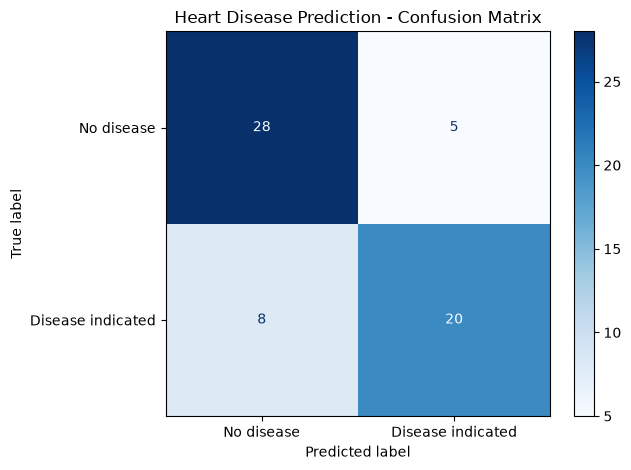

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict the test dataset
y_pred = model.predict(X_test)

# Calculate performance metrics
print("HEART DISEASE MODEL EVALUATION")
print("=" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No disease indicated", "Disease indicated"],
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease indicated"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [5]:
import joblib
import os

# Save the complete trained pipeline
model_filename = "heart_disease_svm_model.pkl"
joblib.dump(model, model_filename)

print("Model saved successfully!")
print("File:", os.path.abspath(model_filename))
print("Model size:", f"{os.path.getsize(model_filename) / 1024:.2f} KB")

Model saved successfully!
File: D:\Python Programes\ML\Uni\ML_assignment_2\ML_Assignment_2\Heart_Disease\heart_disease_svm_model.pkl
Model size: 9.84 KB


In [6]:
import joblib

# Load the saved model
loaded_model = joblib.load("heart_disease_svm_model.pkl")

# Test a sample with the four required features
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]

print("Input features:")
display(sample)

print("Predicted class:", prediction)
print(
    "Prediction meaning:",
    "Disease indicated" if prediction == 1 else "No disease indicated"
)
print("Actual class:", y_test.iloc[0])

Input features:


,age,sex,cp,thalach
219,59.0,1.0,4.0,182.0


Predicted class: 1
Prediction meaning: Disease indicated
Actual class: 0
